# Assignment 1: Logistic Regression on MNIST

- Use Numpy only to construct the Logistic Regression model.
- Train and evaluating (precision, recall, f1) the Logistic Regression model using the Gradient Descent approach **to classify 0 and 1 digit images** on the [MNIST](https://github.com/cvdfoundation/mnist?tab=readme-ov-file) dataset.
- Visualize the loss function of the training process.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Import thư viện
Import các thư viện cần thiết

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import struct

## 2. Hàm đọc MNIST
Xây dựng các hàm đọc ảnh và nhãn

In [4]:

def load_images(filename):
    with open(filename, 'rb') as f:
        magic, num_images, rows, cols = struct.unpack(">IIII", f.read(16))
        images = np.frombuffer(f.read(), dtype=np.uint8)
        images = images.reshape(num_images, rows, cols)
    return images

def load_labels(filename):
    with open(filename, 'rb') as f:
        magic, num_labels = struct.unpack(">II", f.read(8))
        labels = np.frombuffer(f.read(), dtype=np.uint8)
    return labels

## 3. Load dataset
Đọc tập train, test và kiểm tra kích thước của dữ liệu

In [5]:

X_train = load_images("/content/drive/MyDrive/Lab2/data/train-images.idx3-ubyte")
y_train = load_labels("/content/drive/MyDrive/Lab2/data/train-labels.idx1-ubyte")

X_test = load_images("/content/drive/MyDrive/Lab2/data/t10k-images.idx3-ubyte")
y_test = load_labels("/content/drive/MyDrive/Lab2/data/t10k-labels.idx1-ubyte")

print(X_train.shape)
print(y_train.shape)

print(X_test.shape)
print(y_test.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


## 4. Preprocessing
Giữ lại các ảnh chữ số 0, 1, chuyển các ảnh 28x28 thành vecto 784 phần tử và chuẩn hóa các giá trị pixel về khoảng [0, 1]

In [6]:
train_mask = (y_train == 0) | (y_train == 1)
test_mask = (y_test == 0) | (y_test == 1)

X_train = X_train[train_mask]
y_train = y_train[train_mask]

X_test = X_test[test_mask]
y_test = y_test[test_mask]

print(np.unique(y_train))
print(np.unique(y_test))

X_train = X_train.reshape(X_train.shape[0], -1)
X_test = X_test.reshape(X_test.shape[0], -1)

X_train = X_train.astype(np.float64) / 255.0
X_test = X_test.astype(np.float64) / 255.0

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)

[0 1]
[0 1]
X_train shape: (12665, 784)
X_test shape : (2115, 784)


## 5. Logistic Regression bằng NumPy
Xây dụng hàm Logistic Regression bằng NumPy với hàm Sigmoid, Binary Cross-Entropy Loss và Gradient Descent

In [7]:
class LogisticRegression:
    def __init__(self, learning_rate=0.1, epochs=100):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.w = None
        self.b = 0.0
        self.loss_history = []

    def sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def compute_loss(self, y, y_hat):
        eps = 1e-15
        y_hat = np.clip(y_hat, eps, 1 - eps)
        loss = -np.mean(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))
        return loss

    def fit(self, X, y):
        self.loss_history = []
        n_samples, n_features = X.shape
        self.w = np.zeros(n_features)
        self.b = 0.0
        for epoch in range(self.epochs):
            z = X @ self.w + self.b
            y_hat = self.sigmoid(z)

            loss = self.compute_loss(y, y_hat)
            self.loss_history.append(loss)

            error = y_hat - y

            dw = (X.T @ error) / n_samples
            db = np.mean(error)

            self.w -= self.learning_rate * dw
            self.b -= self.learning_rate * db

            if epoch % 10 == 0:
                print(
                    f"Epoch {epoch:3d} | "
                    f"Loss = {loss:.6f}"
                )

    def predict_proba(self, X):
        z = X @ self.w + self.b
        return self.sigmoid(z)

    def predict(self, X):
        probabilities = self.predict_proba(X)
        return (probabilities >= 0.5).astype(int)

## 6. Train model
Huấn luyện mô hình trên tập train và cập nhật trọng số bằng gradient descent qua 100 epoch

In [8]:
model = LogisticRegression(learning_rate=0.1, epochs=100)
model.fit(X_train, y_train)

Epoch   0 | Loss = 0.693147
Epoch  10 | Loss = 0.112864
Epoch  20 | Loss = 0.067832
Epoch  30 | Loss = 0.050569
Epoch  40 | Loss = 0.041241
Epoch  50 | Loss = 0.035327
Epoch  60 | Loss = 0.031208
Epoch  70 | Loss = 0.028157
Epoch  80 | Loss = 0.025795
Epoch  90 | Loss = 0.023906


In [9]:
def evaluate(y_true, y_pred):
    TP = np.sum((y_true == 1) & (y_pred == 1))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))

    accuracy = ((TP + TN) / (TP + TN + FP + FN))
    precision = (TP / (TP + FP + 1e-15))
    recall = (TP / (TP + FN + 1e-15))
    f1 = (2 * precision * recall / (precision + recall + 1e-15))

    print("TP =", TP)
    print("TN =", TN)
    print("FP =", FP)
    print("FN =", FN)

    print()
    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-score  : {f1:.4f}")

## 7. Evaluation
Tính các giá trị TP, TN, FP, FN và các độ đo Accuracy, Precision, Recall, F1-score

In [10]:
y_pred = model.predict(X_test)

print("Actual    :", y_test[:20])
print("Predicted :", y_pred[:20])

print("\nEvaluation:")
evaluate(y_test, y_pred)

Actual    : [1 0 1 0 0 1 0 0 1 1 1 1 1 1 0 1 0 0 1 1]
Predicted : [1 0 1 0 0 1 0 0 1 1 1 1 1 1 0 1 0 0 1 1]

Evaluation:
TP = 1135
TN = 978
FP = 2
FN = 0

Accuracy  : 0.9991
Precision : 0.9982
Recall    : 1.0000
F1-score  : 0.9991


## 8. Plot Training Loss


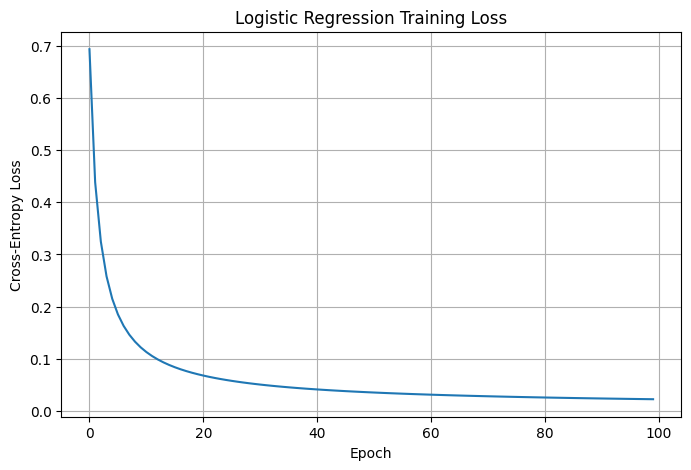

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(model.loss_history)
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Logistic Regression Training Loss")
plt.grid()
plt.show()